In [ ]:
import pandas as pd
import numpy as np
import mglearn
import matplotlib.pyplot as plt

In [26]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.svm import SVC

cancer = load_breast_cancer()
x_train, x_test, y_train, y_test = train_test_split(cancer.data,
                                                     cancer.target, 
                                                     random_state=0
                                                    )

from sklearn.pipeline import Pipeline

#ここでは二つのステップを作っている
pipe = Pipeline([
    ("scaler",MinMaxScaler()),
    ("svm",SVC())
])

pipe.fit(x_train,y_train)
print()

In [27]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "svm__C": [0.001, 0.01, 0.1, 1, 10, 100],
    "svm__gamma": [0.001, 0.01, 0.1, 1, 10, 100]
}

grid = GridSearchCV(
    pipe,
    param_grid=param_grid,
    cv=5
)

grid.fit(x_train,y_train)

print("Best cross-validation accuracy:{:.2f}".format(grid.best_score_))
print("Test set score:{:.2f}".format(grid.score(x_test,y_test)))
print("Best parameters:{}".format(grid.best_params_))

Best cross-validation accuracy:0.98
Test set score:0.97
Best parameters:{'svm__C': 1, 'svm__gamma': 1}


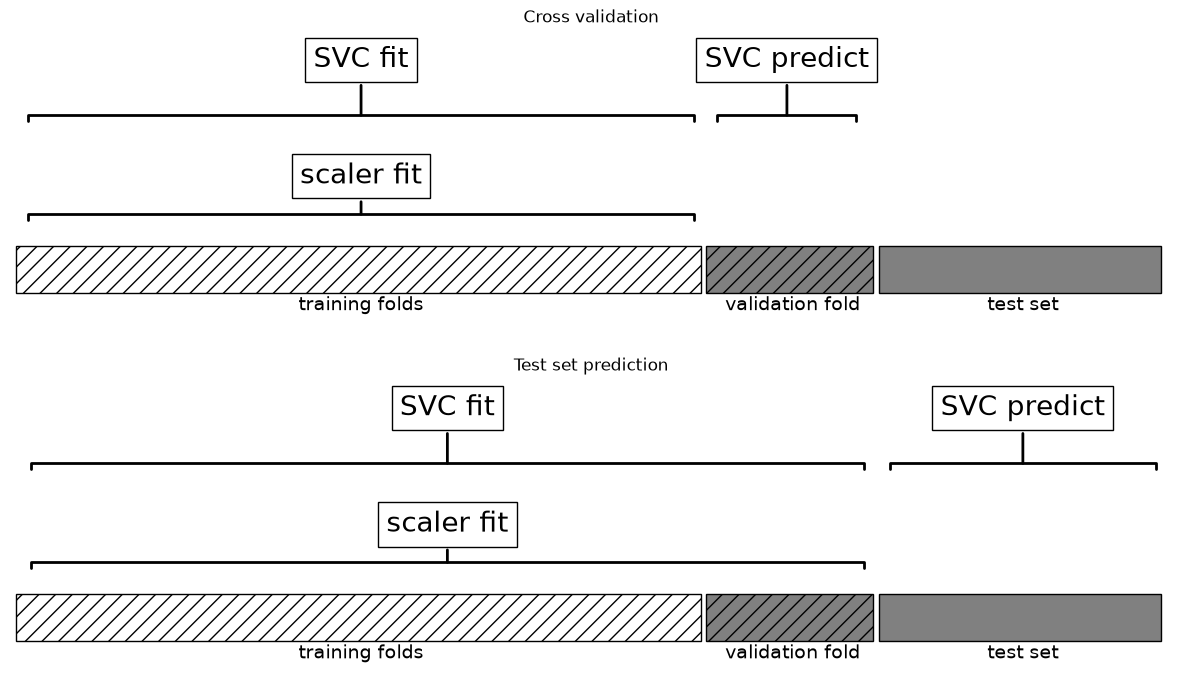

In [28]:
mglearn.plots.plot_proper_processing()

- 情報リークの影響

In [29]:
#10000の特徴量をもつ100サンプルの合成回帰タスクを考える
#すべてのデータを独立のガウス分布からサンプリングする
#レスポンスもガウス分布からサンプリングする

rnd = np.random.RandomState(seed=0)
x = rnd.normal(size=(100,10000))
y = rnd.normal(size=(100,))

#データセットの作り方からいって、データｘとターゲットｙには何の関係もない
#したがって、このデータセットから学習できることはないはずである

from sklearn.feature_selection import SelectPercentile, f_regression

#SelectPercentile特徴量抽出を行って、500個の最も情報量の多い特徴量を抽出する
select = SelectPercentile(
    score_func = f_regression,
    percentile = 5
).fit(x,y)

x_selected = select.transform(x)
print("x_selected.shape:{}".format(x_selected.shape))



x_selected.shape:(100, 500)


In [30]:
from sklearn.linear_model import Ridge
from sklearn.model_selection import cross_val_score

#交差検証で得られた平均R^2は0.91
#しかし、データは完全ランダムなのであるから、これは明らかに正しくない
#交差検証の外で特徴量抽出を行ったので、訓練セットもテストセットでもターゲットに相関のある特徴量が得られてしまった

print("Cross-validation accuracy(cv only on ride):{:.2f}".format(np.mean(cross_val_score(Ridge(),x_selected,y,cv=5))))

Cross-validation accuracy(cv only on ride):0.91


In [31]:
#パイプラインを使って適切な交差検証を行った場合と比較する

from sklearn.pipeline import Pipeline

pipe = Pipeline([
    ("select", SelectPercentile(score_func=f_regression,percentile=5)),
    ("ridge",Ridge())
])

print("Cross-validation accuracy(cv on pipeline):{:.2f}".format(np.mean(cross_val_score(pipe,x,y,cv=5))))

Cross-validation accuracy(cv on pipeline):-0.25
